# ЛР1, ч.2 - кластеризация и визуализация своего датасета
Вариант 8 (свой датасет): **Wine** - 178 вин, 13 химических признаков, 3 сорта.
Класс `ClusteringVisualizer` - в `multidim_visualization.py`.

## Окружение

In [1]:
%pip install -q umap-learn plotly

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys

if not os.path.exists("multidim_visualization.py"):
    try:
        from google.colab import files  # работает только в Google Colab
        print("Загрузите файл multidim_visualization.py")
        files.upload()
    except ImportError:
        raise FileNotFoundError("Положите multidim_visualization.py в одну папку с ноутбуком")

sys.path.insert(0, os.getcwd())

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import importlib
import multidim_visualization as mv
importlib.reload(mv)
from multidim_visualization import ClusteringVisualizer, HighDimVisualizer, HAS_UMAP

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
print("UMAP доступен:", HAS_UMAP)

UMAP доступен: True


## Данные
У Wine признаки в разных единицах (пролин ~750, hue ~1), поэтому StandardScaler.

In [4]:
viz = ClusteringVisualizer.from_sklearn("wine", dataset_name="Wine", scaling="standard",
                                        random_state=42)
viz.describe_data()

Набор данных: Wine
  Объектов: 178, признаков после предобработки: 13
  Масштабирование: standard
  Классов: 3
                 class_0: 59 (33.1%)
                 class_1: 71 (39.9%)
                 class_2: 48 (27.0%)


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83
malic_acid,178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80
ash,178.0,2.367,0.274,1.36,2.210,2.360,2.558,3.23
alcalinity_of_ash,178.0,19.495,3.340,10.60,17.200,19.500,21.500,30.00
magnesium,178.0,99.742,14.282,70.00,88.000,98.000,107.000,162.00
total_phenols,178.0,2.295,0.626,0.98,1.742,2.355,2.800,3.88
flavanoids,178.0,2.029,0.999,0.34,1.205,2.135,2.875,5.08
nonflavanoid_phenols,178.0,0.362,0.124,0.13,0.270,0.340,0.438,0.66
proanthocyanins,178.0,1.591,0.572,0.41,1.250,1.555,1.950,3.58
color_intensity,178.0,5.058,2.318,1.28,3.220,4.690,6.200,13.00


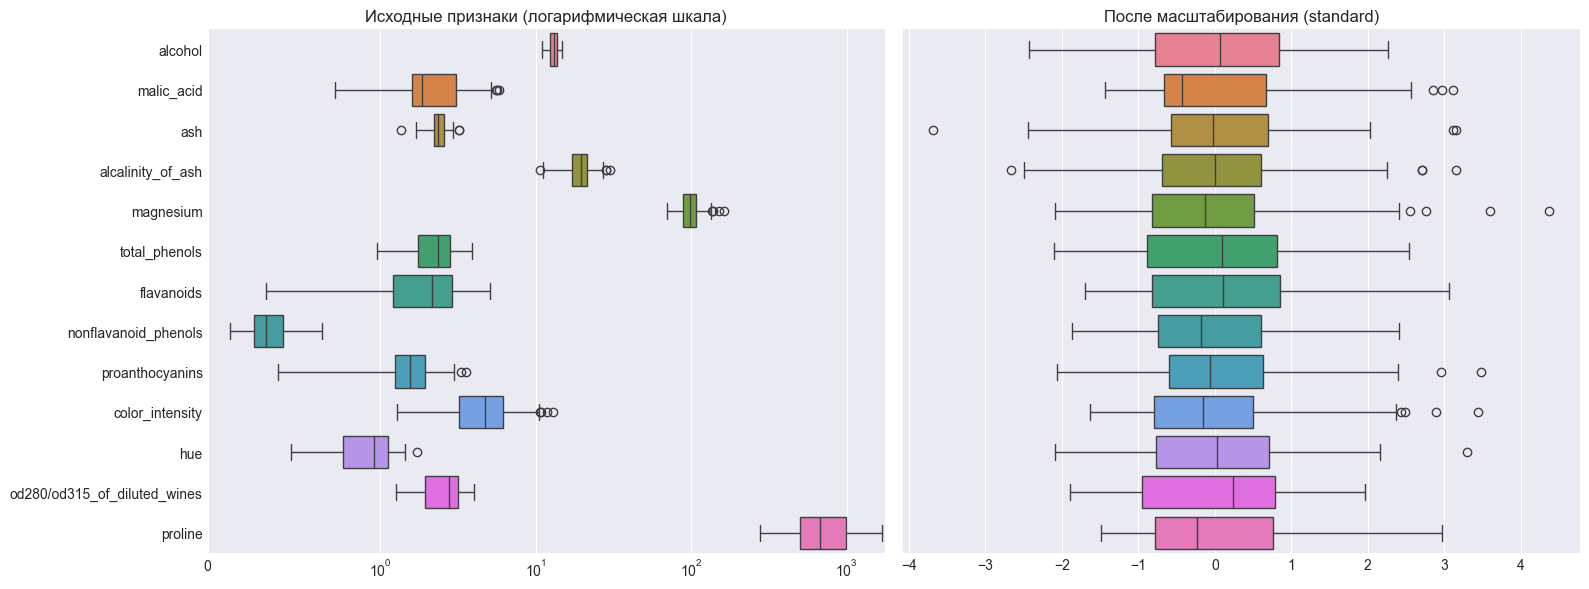

In [5]:
viz.plot_scaling_effect()

Слева сырые признаки (лог. шкала), справа после стандартизации - масштабы выровнялись.

Самые информативные признаки (F-тест): ['flavanoids', 'proline', 'od280/od315_of_diluted_wines', 'alcohol', 'color_intensity']

1. Парные диаграммы рассеяния (PairPlot)


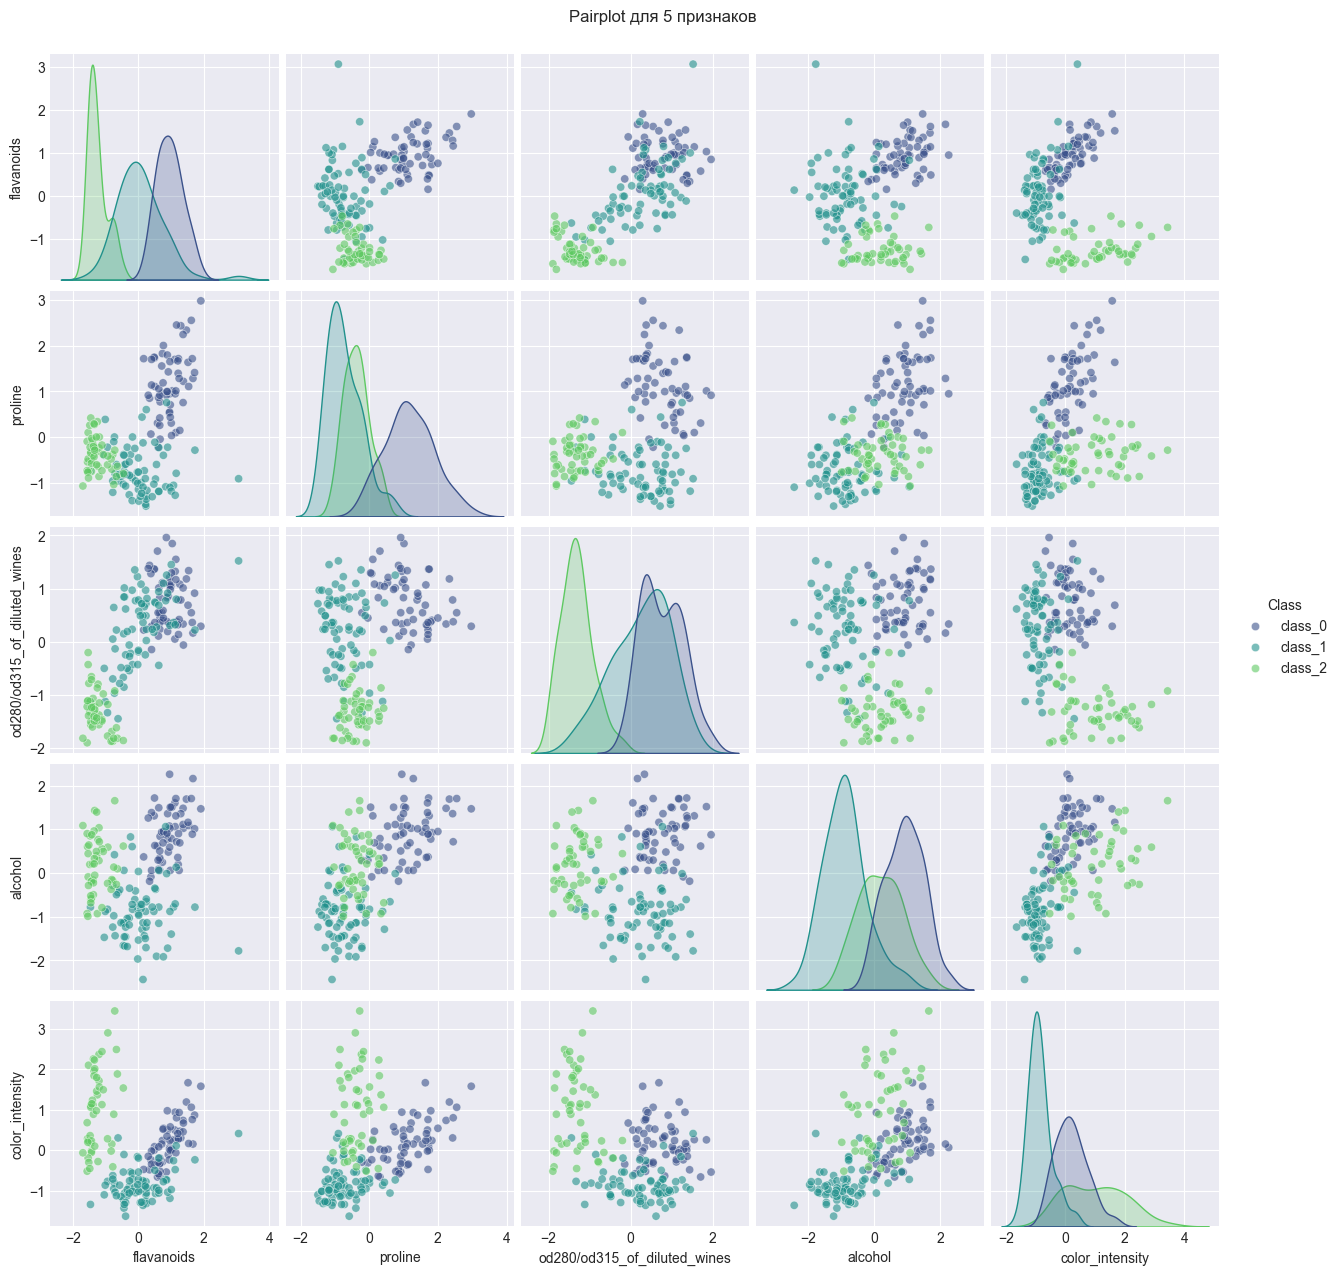


2. Тепловая карта корреляций


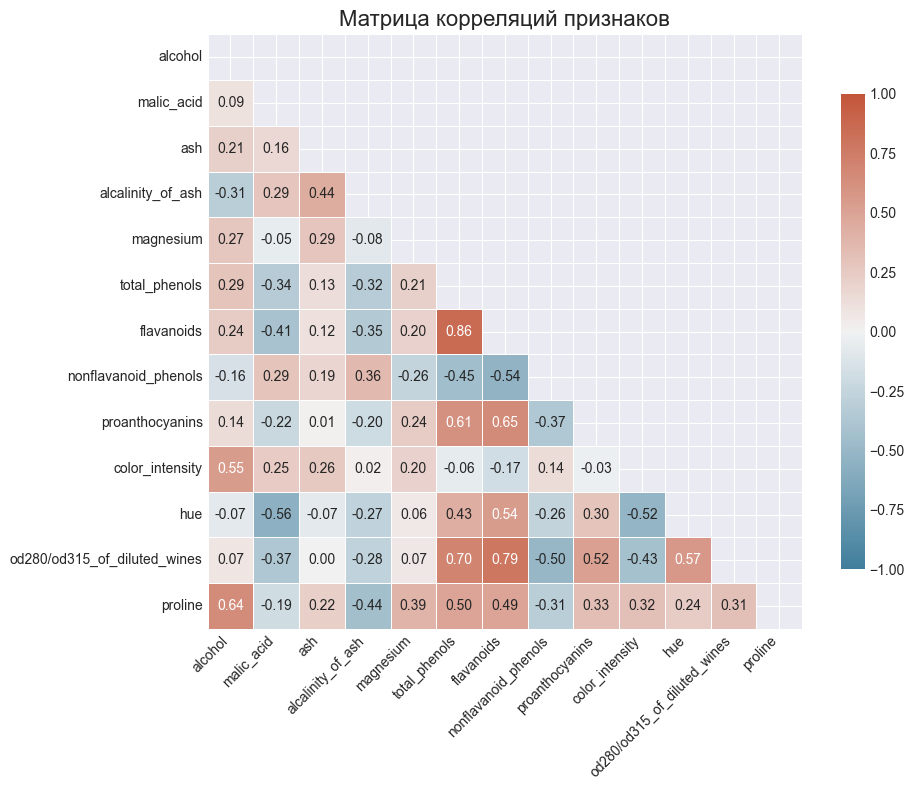

In [6]:
viz.plot_eda(n_features=5)

- Самые разделяющие признаки по F-тесту: flavanoids, proline, od280, alcohol, color_intensity.
- Фенольные признаки сильно коррелируют (r ≈ 0.6–0.86).

## Подбор k

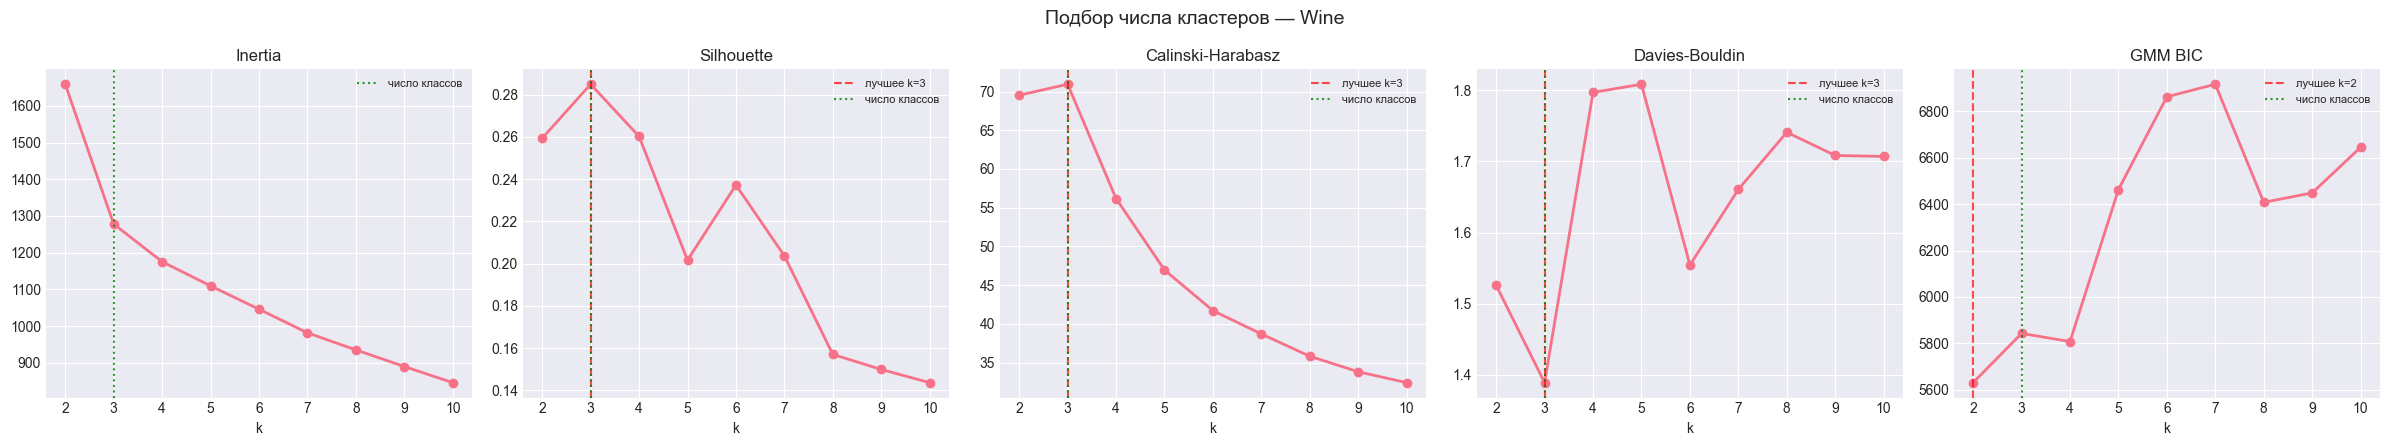

Рекомендация по силуэту: k = 3


,Inertia,Silhouette,Calinski-Harabasz,Davies-Bouldin,GMM BIC
k,,,,,
2,1658.759,0.259,69.523,1.526,5629.573
3,1277.928,0.285,70.940,1.389,5842.330
4,1175.428,0.260,56.181,1.797,5806.820
5,1109.513,0.202,46.952,1.808,6463.002
6,1046.002,0.237,41.701,1.554,6863.554
7,981.595,0.204,38.686,1.661,6917.547
8,935.201,0.157,35.805,1.741,6407.919
9,889.893,0.150,33.807,1.708,6448.656
10,845.895,0.144,32.397,1.707,6645.620


In [7]:
k_table = viz.find_optimal_k(range(2, 11))
k_table.round(3)

Локоть, силуэт (0.285), CH и DB указывают на k = 3 - совпадает с числом сортов. BIC GMM выбирает k = 2: при n = 178 штраф за параметры полных ковариаций большой.

## eps для DBSCAN

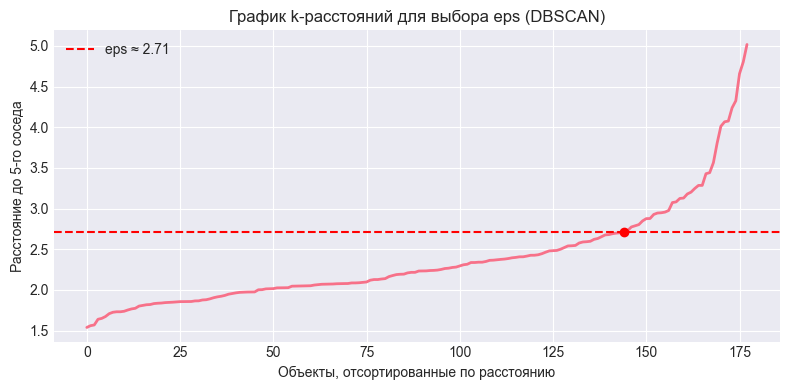

eps по колену графика k-расстояний: 2.710


In [8]:
eps_13d = viz.estimate_dbscan_eps(min_samples=5)
print(f"eps по колену графика k-расстояний: {eps_13d:.3f}")

## Кластеризация, k = 3

In [9]:
labels = viz.fit_clustering(n_clusters=3, dbscan_min_samples=5)

        KMeans: найдено кластеров = 3
 Agglomerative: найдено кластеров = 3
           GMM: найдено кластеров = 3
        DBSCAN: найдено кластеров = 1


DBSCAN в 13D нашёл один кластер: в высокой размерности плотность «размазана». Пробую DBSCAN на 2D-вложении UMAP:

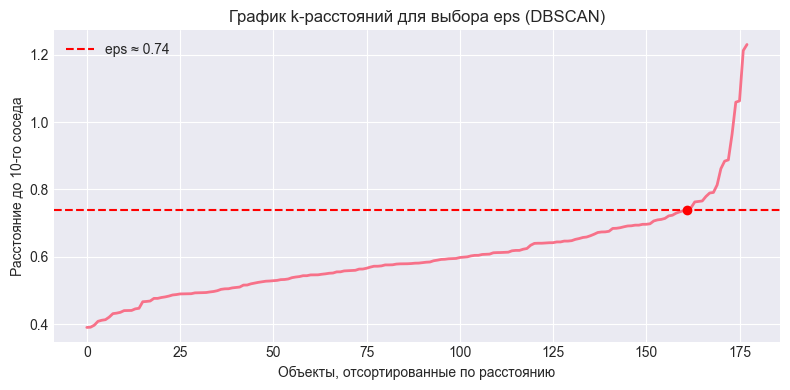

DBSCAN (UMAP): eps=0.738, min_samples=10, найдено кластеров = 3


In [10]:
if HAS_UMAP:
    viz.fit_dbscan_on_embedding("UMAP", n_components=2, min_samples=10)

## Метрики

In [11]:
metrics = viz.evaluate_clustering()
metrics.round(3)

,Clusters,"Noise, %",Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI,AMI,Homogeneity,Completeness,V-measure,Accuracy
Algorithm,,,,,,,,,,,
KMeans,3,0.000,0.285,70.940,1.389,0.897,0.875,0.879,0.873,0.876,0.966
Agglomerative,3,0.000,0.277,67.647,1.419,0.790,0.784,0.790,0.783,0.786,0.927
GMM,3,0.000,0.284,70.688,1.394,0.880,0.859,0.864,0.858,0.861,0.961
DBSCAN,1,10.112,NaN,NaN,NaN,0.000,0.089,0.063,0.208,0.096,0.421
DBSCAN (UMAP),3,0.000,0.278,69.219,1.382,0.774,0.772,0.778,0.770,0.774,0.921


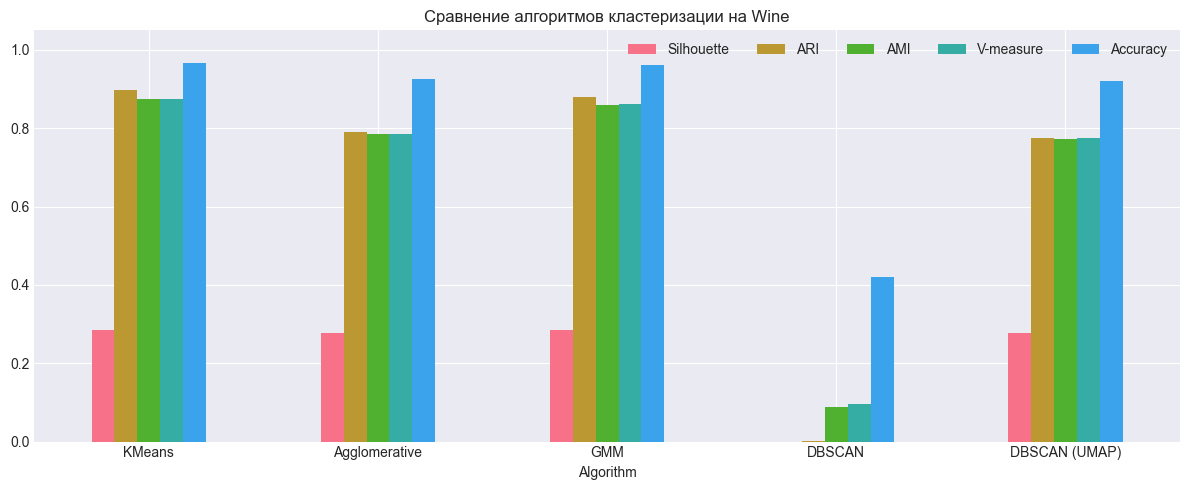

Лучший алгоритм по ARI: KMeans


In [12]:
# Визуальное сравнение алгоритмов по основным метрикам
cols = ["Silhouette", "ARI", "AMI", "V-measure", "Accuracy"]
ax = metrics[cols].plot(kind="bar", figsize=(12, 5), rot=0)
ax.set_title("Сравнение алгоритмов кластеризации на Wine")
ax.set_ylim(0, 1.05)
ax.legend(loc="upper right", ncol=5)
plt.tight_layout()
plt.show()
print("Лучший алгоритм по ARI:", viz.best_algorithm())

- KMeans лучший: ARI ≈ 0.90, accuracy ≈ 0.97.
- GMM ≈ 0.88, Ward ≈ 0.79.
- DBSCAN в 13D - ARI 0; на UMAP - 3 кластера, ARI ≈ 0.77.
- Силуэт у всех ≈ 0.28: по внутренним метрикам алгоритмы почти не различаются.

## 2D-проекции

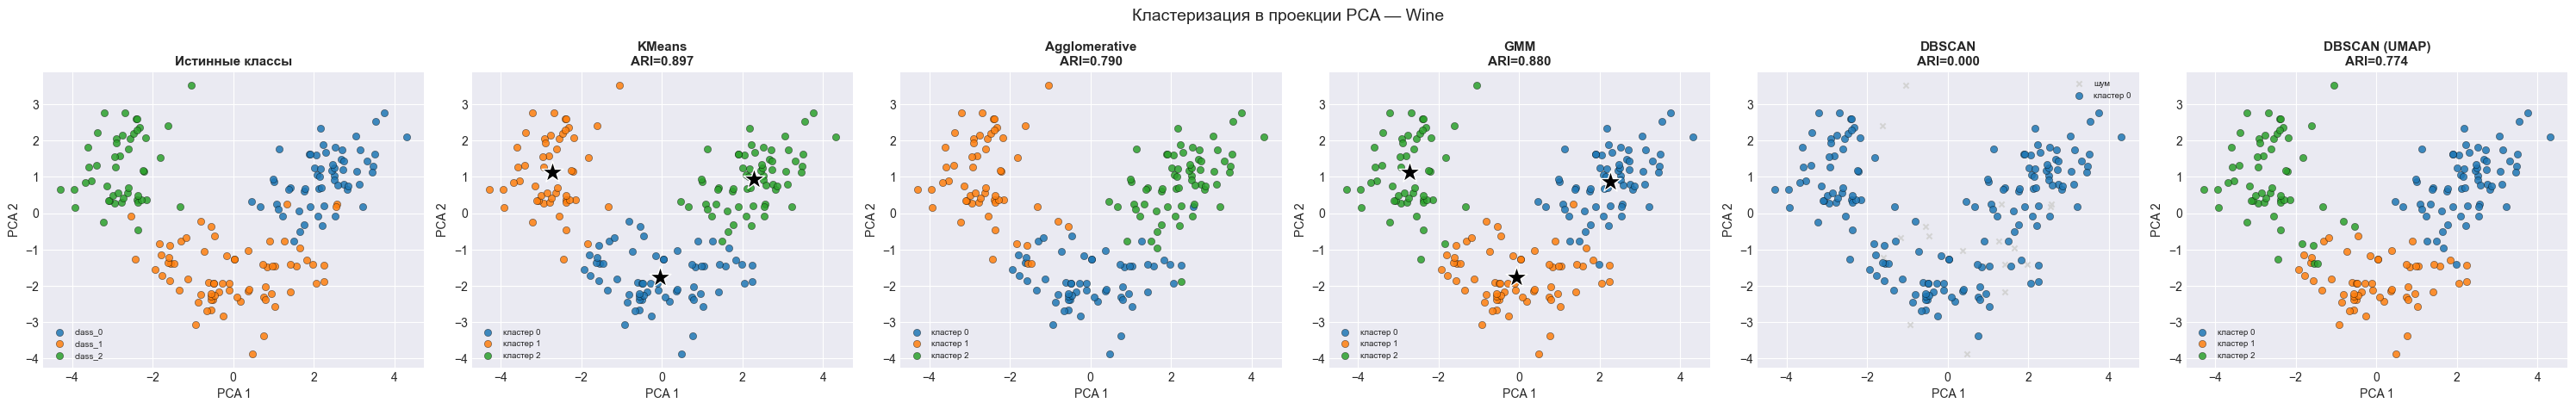

In [13]:
viz.plot_clusters_2d("PCA")

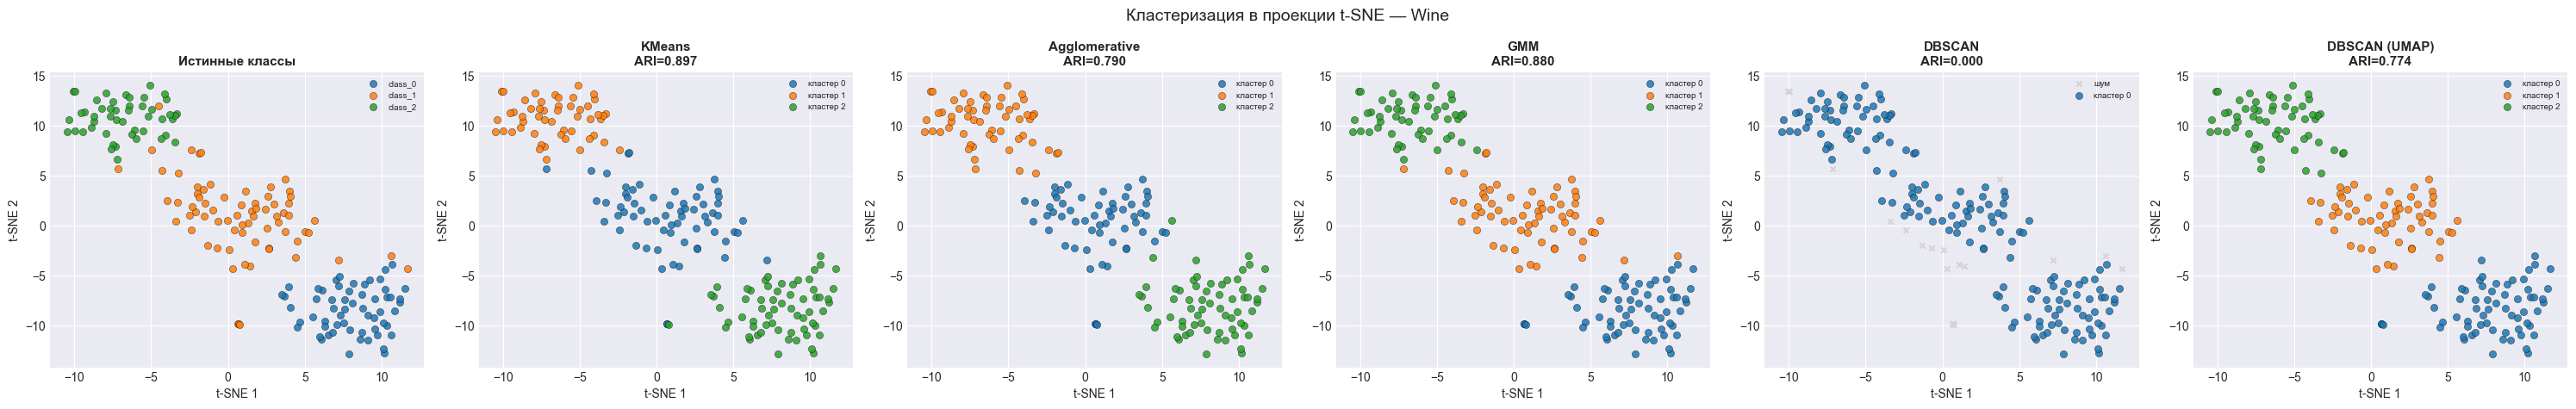

In [14]:
viz.plot_clusters_2d("t-SNE")

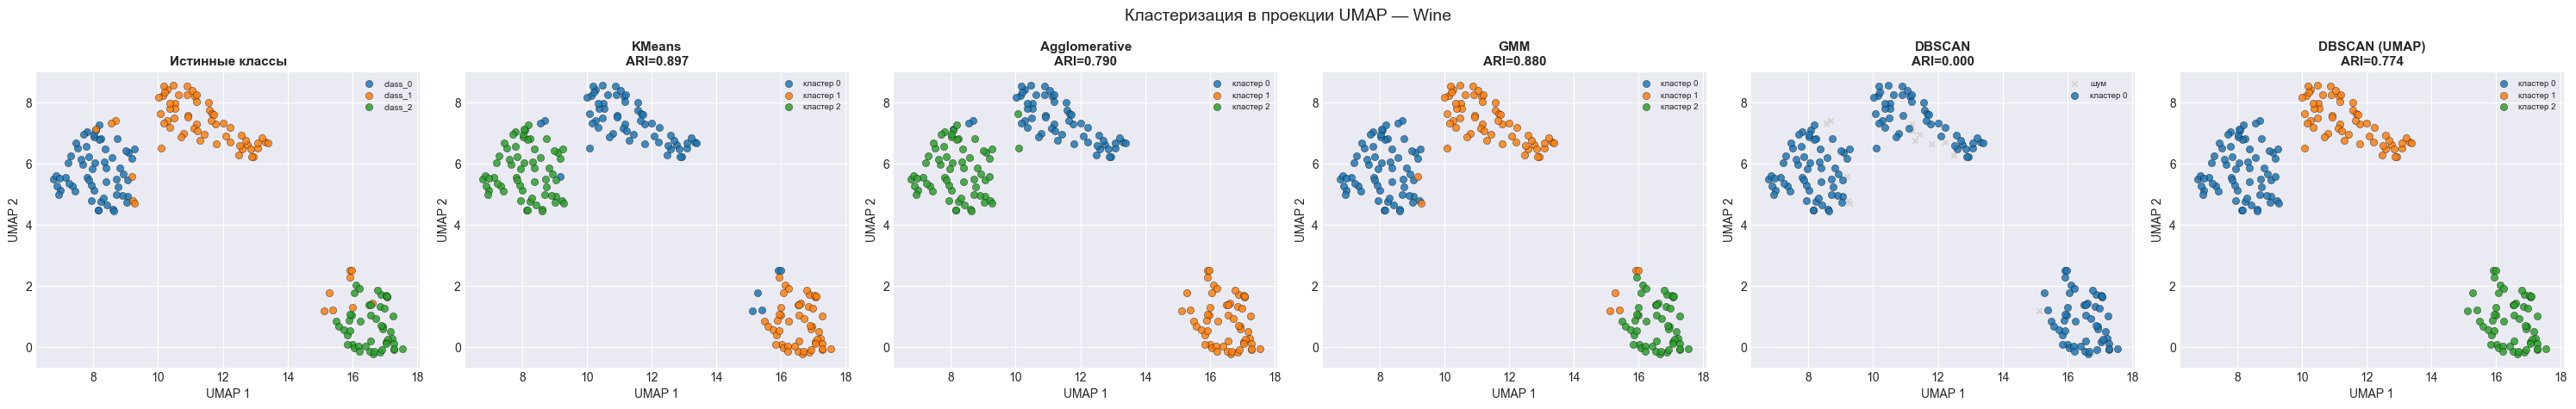

In [15]:
if HAS_UMAP:
    viz.plot_clusters_2d("UMAP")

- PCA: сорта лежат дугой, class_1 посередине - ошибки как раз на его границах.
- t-SNE и UMAP разводят группы сильнее, чем есть на самом деле.

## 3D

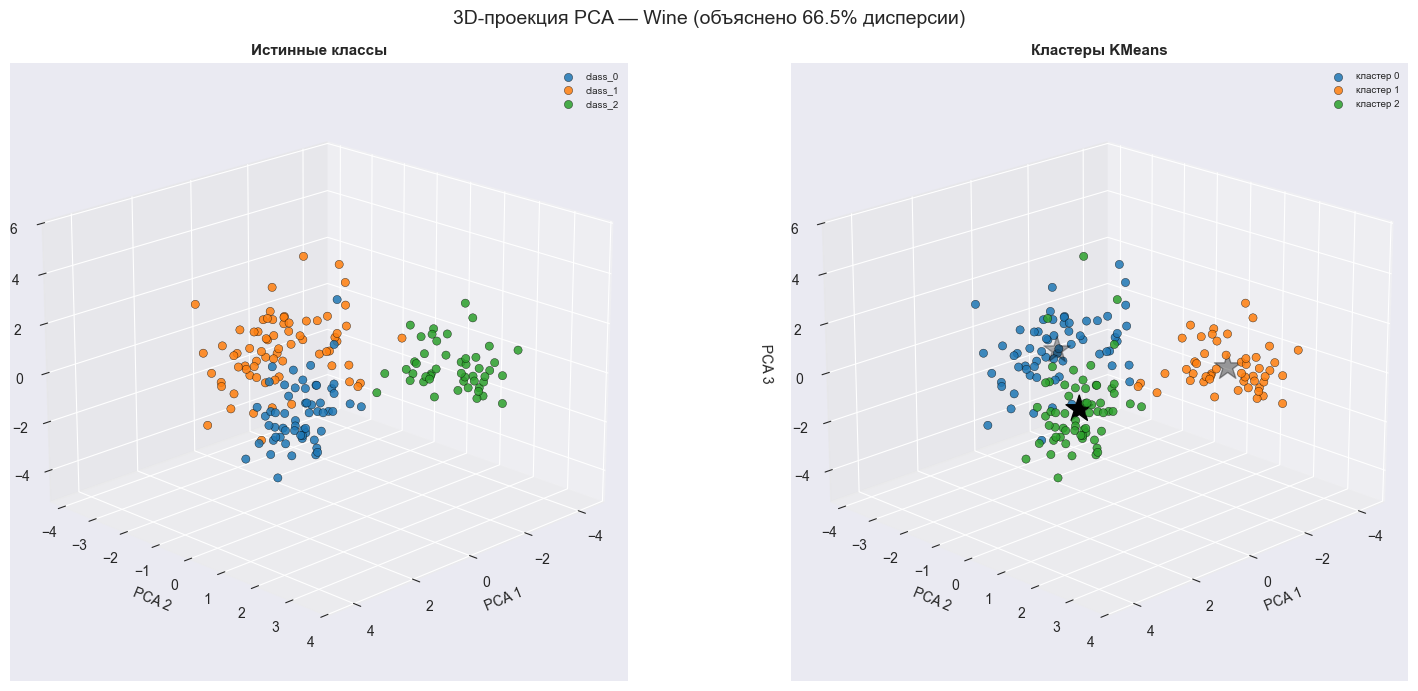

In [16]:
viz.plot_clusters_3d("PCA", algorithm="KMeans")

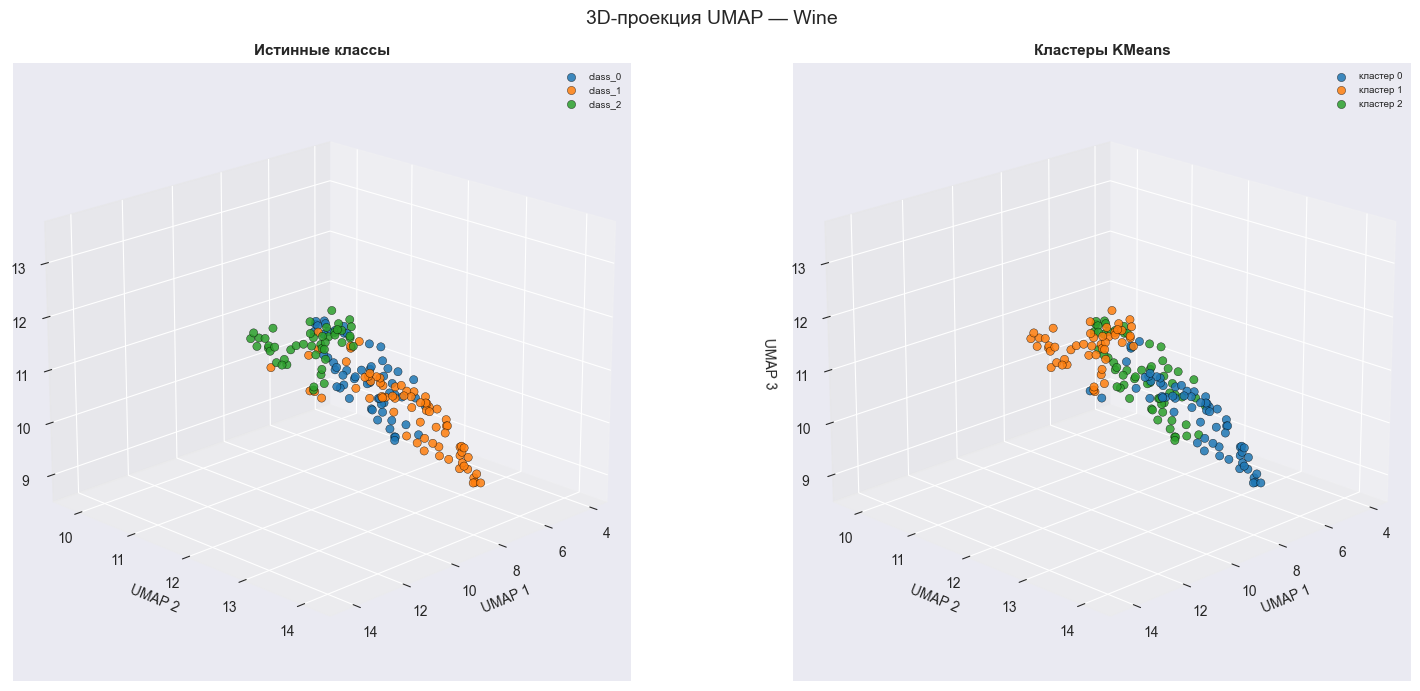

In [17]:
if HAS_UMAP:
    viz.plot_clusters_3d("UMAP", algorithm="KMeans")

Plotly: цвет - кластер, маркер - сорт; сохраняю в html.

In [18]:
fig3d = viz.plot_interactive_3d_clusters("PCA", algorithm="KMeans",
                                         filename="wine_kmeans_3d.html")

Интерактивный график сохранён: wine_kmeans_3d.html


## Интерпретация

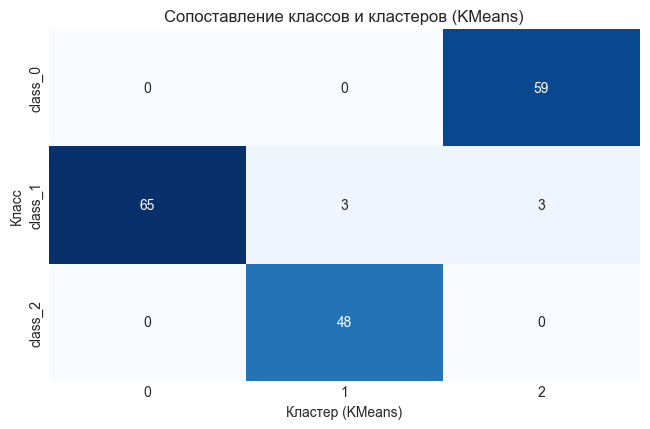

Кластер (KMeans),0,1,2
Класс,,,
class_0,0,0,59
class_1,65,3,3
class_2,0,48,0


In [19]:
viz.plot_contingency("KMeans")

Ошибаемся только на class_1: 6 вин из 178.

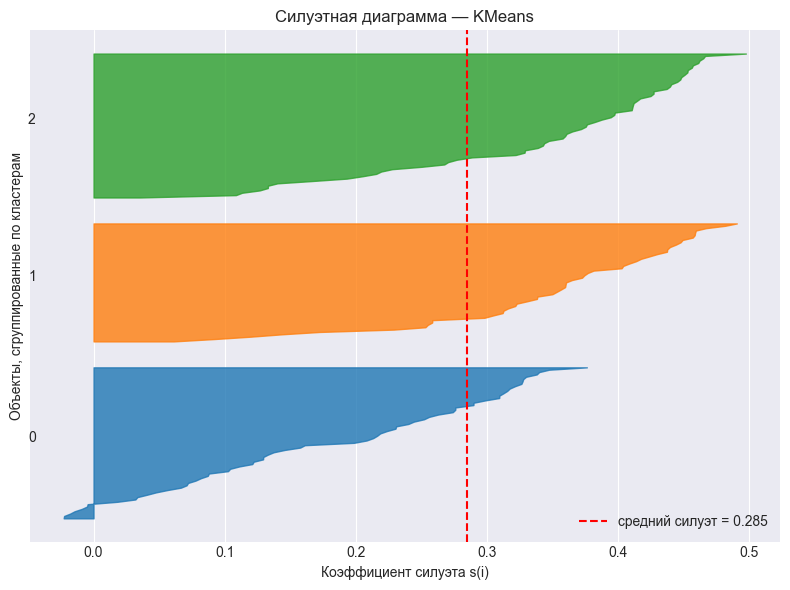

In [20]:
viz.plot_silhouette_diagram("KMeans")

Профили кластеров - средние z-оценки признаков:

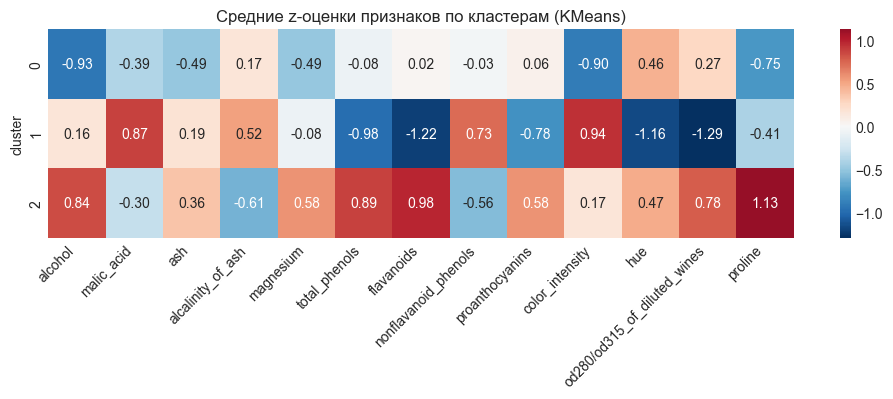

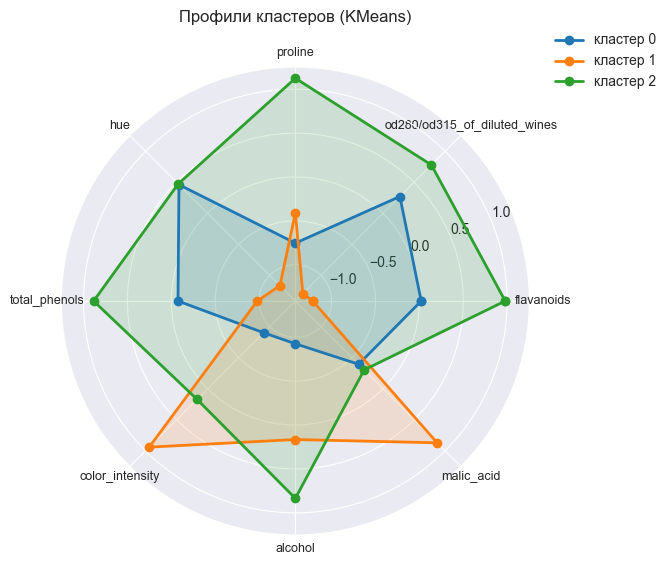

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
cluster,,,,,,,,,,,,,
0,-0.93,-0.39,-0.49,0.17,-0.49,-0.08,0.02,-0.03,0.06,-0.90,0.46,0.27,-0.75
1,0.16,0.87,0.19,0.52,-0.08,-0.98,-1.22,0.73,-0.78,0.94,-1.16,-1.29,-0.41
2,0.84,-0.30,0.36,-0.61,0.58,0.89,0.98,-0.56,0.58,0.17,0.47,0.78,1.13


In [21]:
profile = viz.plot_cluster_profiles("KMeans")
profile.round(2)

- class_0: много алкоголя, пролина, флавоноидов;
- class_1: «лёгкие» - мало алкоголя, пролина, цвета;
- class_2: яркий цвет, мало флавоноидов, hue и od280.

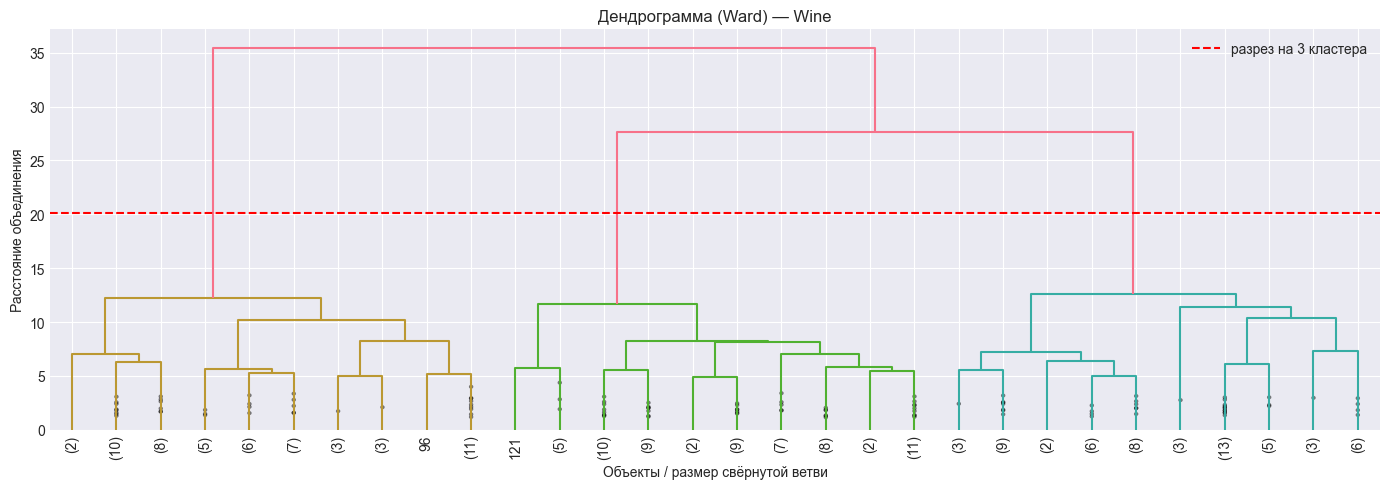

In [22]:
viz.plot_dendrogram(p=30)

Дендрограмма: три крупные ветви, разрез → 3 кластера.

## Методы исходного класса


9. Сравнение методов уменьшения размерности
  Применяем PCA...
  Применяем t-SNE...


  Применяем MDS...
  Применяем Isomap...
  Применяем UMAP...


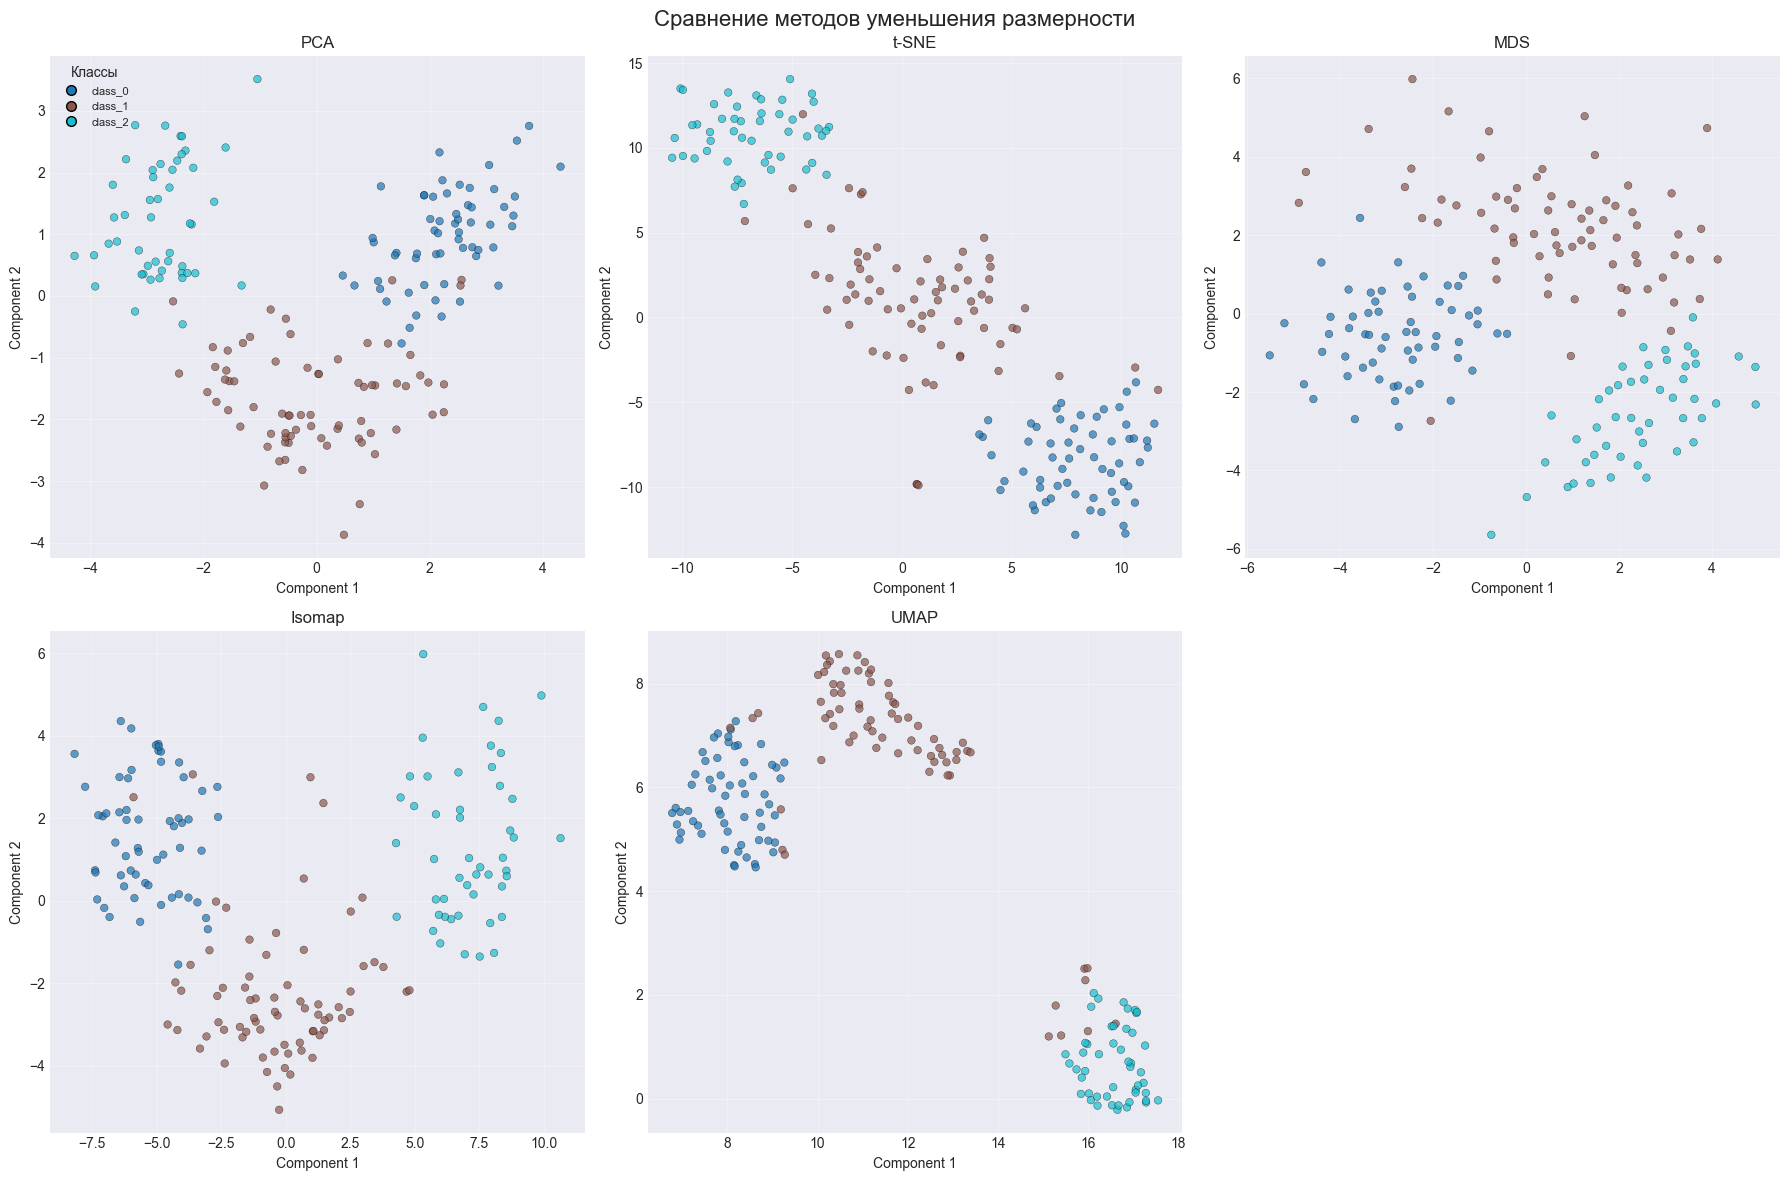

In [23]:
viz.compare_dim_reduction_methods(viz.X, viz.y)

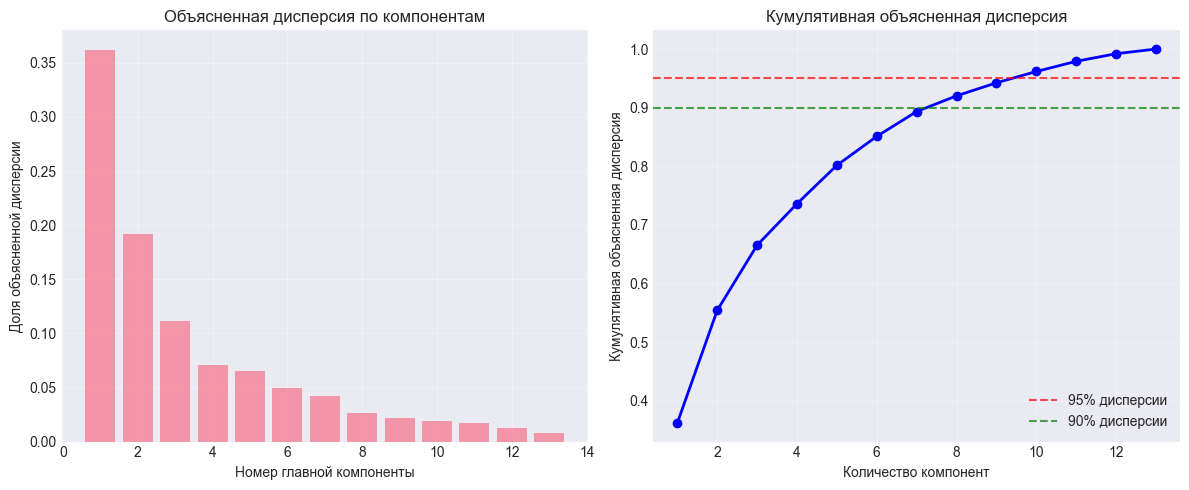

  Для 80% дисперсии нужно компонент: 5
  Для 90% дисперсии нужно компонент: 8
  Для 95% дисперсии нужно компонент: 10


In [24]:
viz.plot_explained_variance(viz.X)

80 % дисперсии - 5 компонент, 90 % - 8; 2D-PCA объясняет ≈55 %, 3D - ≈67 %.

## Проверка на другом датасете через CSV

Набор данных: Breast Cancer (CSV)
  Объектов: 569, признаков после предобработки: 30
  Масштабирование: standard
  Классов: 2
                  benign: 357 (62.7%)
               malignant: 212 (37.3%)


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


        KMeans: найдено кластеров = 2
 Agglomerative: найдено кластеров = 2
           GMM: найдено кластеров = 2


,Clusters,"Noise, %",Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI,AMI,Homogeneity,Completeness,V-measure,Accuracy
Algorithm,,,,,,,,,,,
KMeans,2,0.0,0.343,267.692,1.321,0.654,0.532,0.525,0.540,0.532,0.905
Agglomerative,2,0.0,0.339,248.629,1.370,0.575,0.456,0.446,0.468,0.457,0.880
GMM,2,0.0,0.314,247.284,1.377,0.774,0.661,0.662,0.660,0.661,0.940


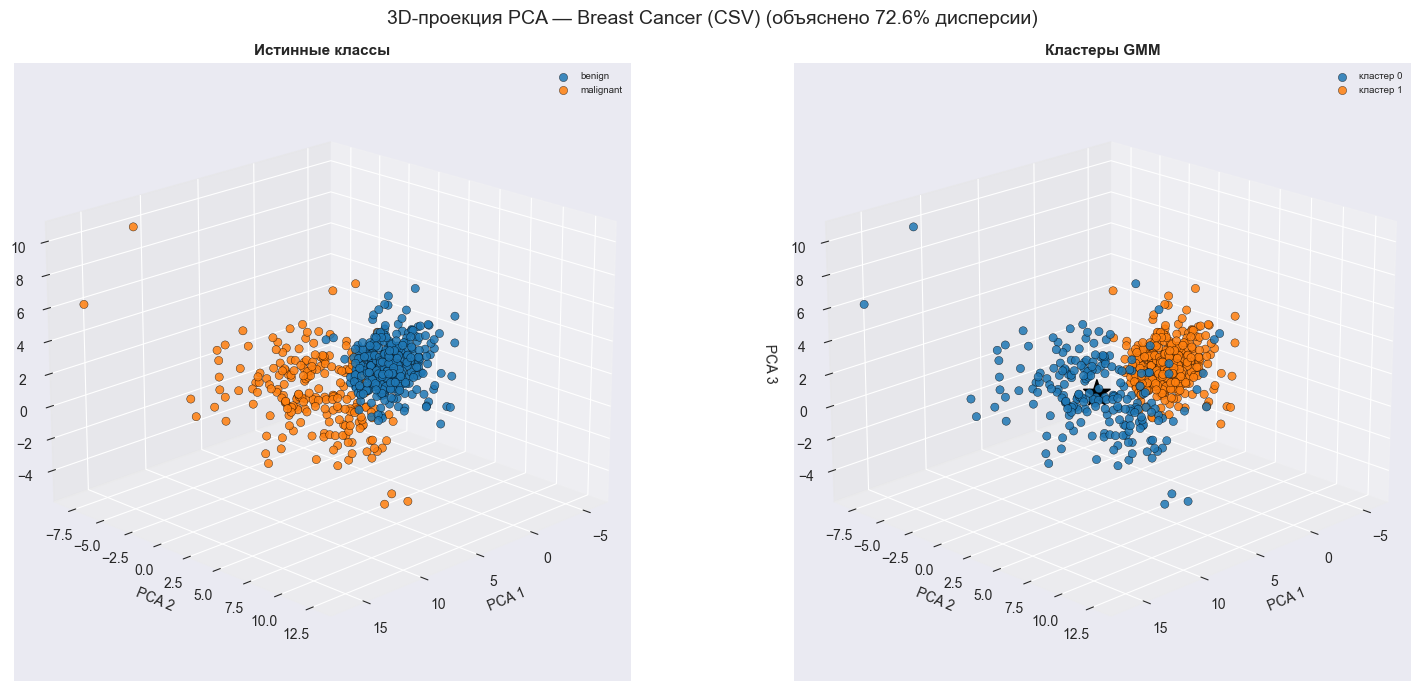

In [25]:
from sklearn.datasets import load_breast_cancer

bc = load_breast_cancer(as_frame=True)
bc_df = bc.frame.copy()
bc_df["diagnosis"] = bc_df["target"].map({0: "malignant", 1: "benign"})
bc_df.drop(columns="target").to_csv("breast_cancer.csv", index=False)

viz_bc = ClusteringVisualizer.from_csv("breast_cancer.csv", target="diagnosis",
                                       dataset_name="Breast Cancer (CSV)")
viz_bc.describe_data()
viz_bc.fit_clustering(algorithms=("KMeans", "Agglomerative", "GMM"))
display(viz_bc.evaluate_clustering().round(3))
viz_bc.plot_clusters_3d("PCA")

На Breast Cancer лучше GMM (ARI ≈ 0.77), чем KMeans (≈ 0.65): облака разной формы и размера.

## Весь конвейер одной командой

КЛАСТЕРИЗАЦИЯ И ВИЗУАЛИЗАЦИЯ: Wine
Набор данных: Wine
  Объектов: 178, признаков после предобработки: 13
  Масштабирование: standard
  Классов: 3
                 class_0: 59 (33.1%)
                 class_1: 71 (39.9%)
                 class_2: 48 (27.0%)


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83
malic_acid,178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80
ash,178.0,2.367,0.274,1.36,2.210,2.360,2.558,3.23
alcalinity_of_ash,178.0,19.495,3.340,10.60,17.200,19.500,21.500,30.00
magnesium,178.0,99.742,14.282,70.00,88.000,98.000,107.000,162.00
total_phenols,178.0,2.295,0.626,0.98,1.742,2.355,2.800,3.88
flavanoids,178.0,2.029,0.999,0.34,1.205,2.135,2.875,5.08
nonflavanoid_phenols,178.0,0.362,0.124,0.13,0.270,0.340,0.438,0.66
proanthocyanins,178.0,1.591,0.572,0.41,1.250,1.555,1.950,3.58
color_intensity,178.0,5.058,2.318,1.28,3.220,4.690,6.200,13.00


Самые информативные признаки (F-тест): ['flavanoids', 'proline', 'od280/od315_of_diluted_wines', 'alcohol', 'color_intensity']

1. Парные диаграммы рассеяния (PairPlot)


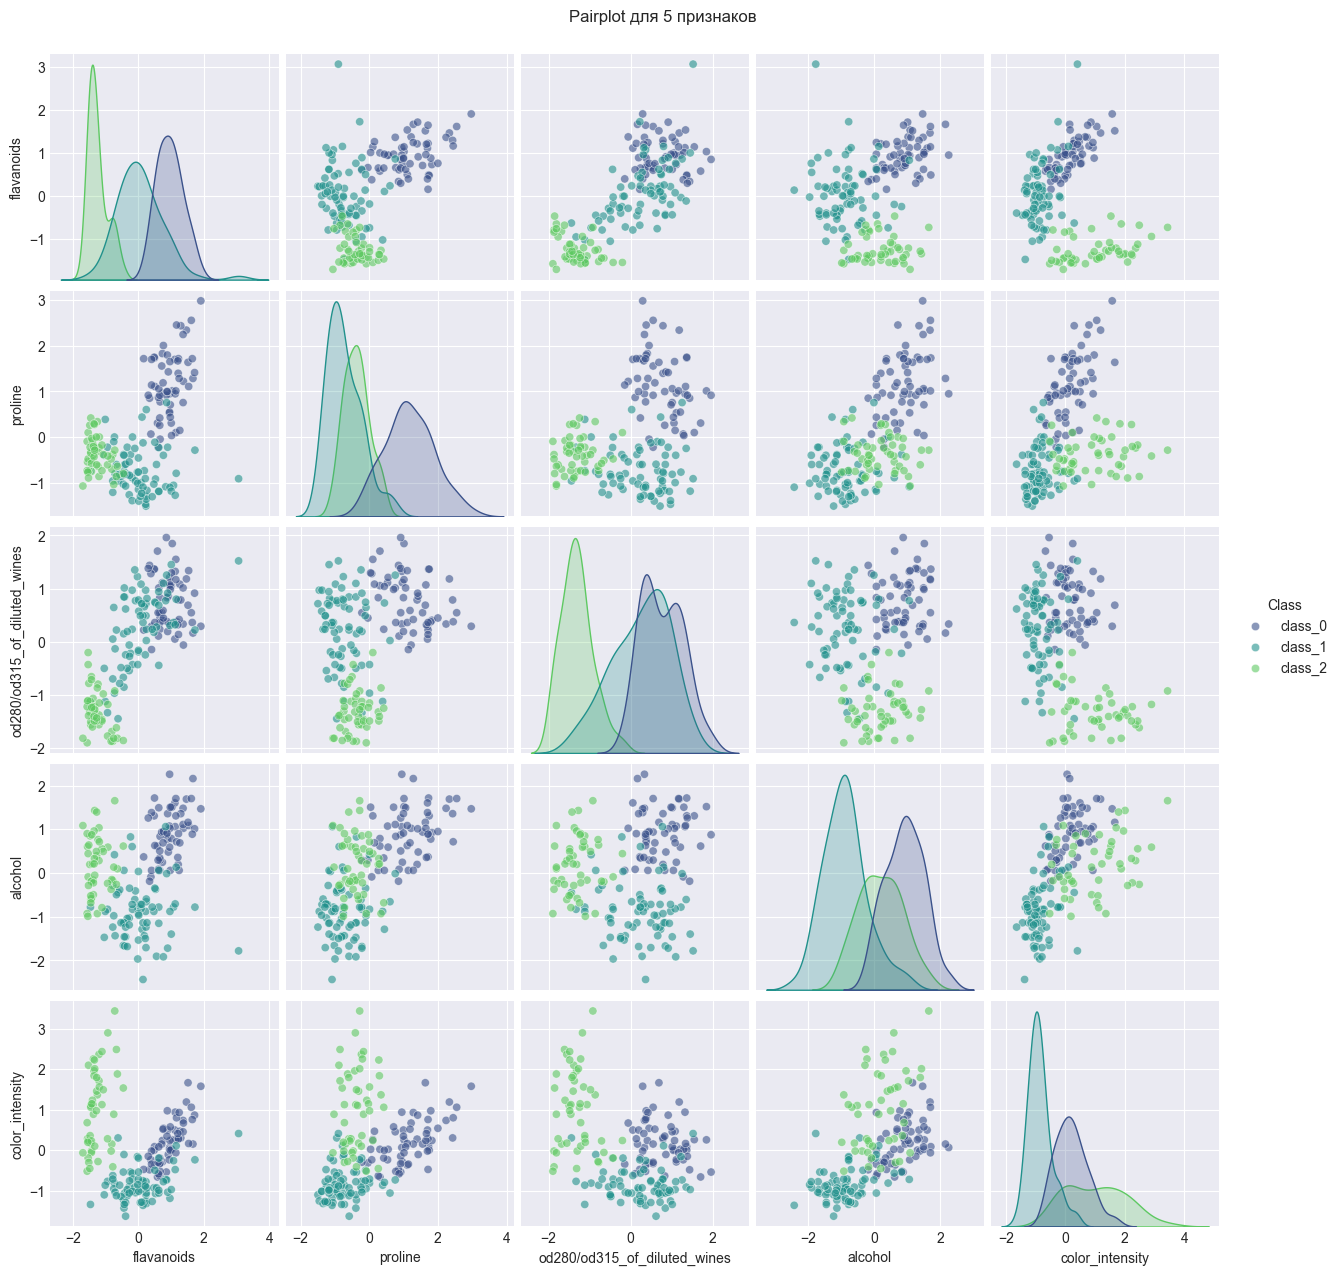


2. Тепловая карта корреляций


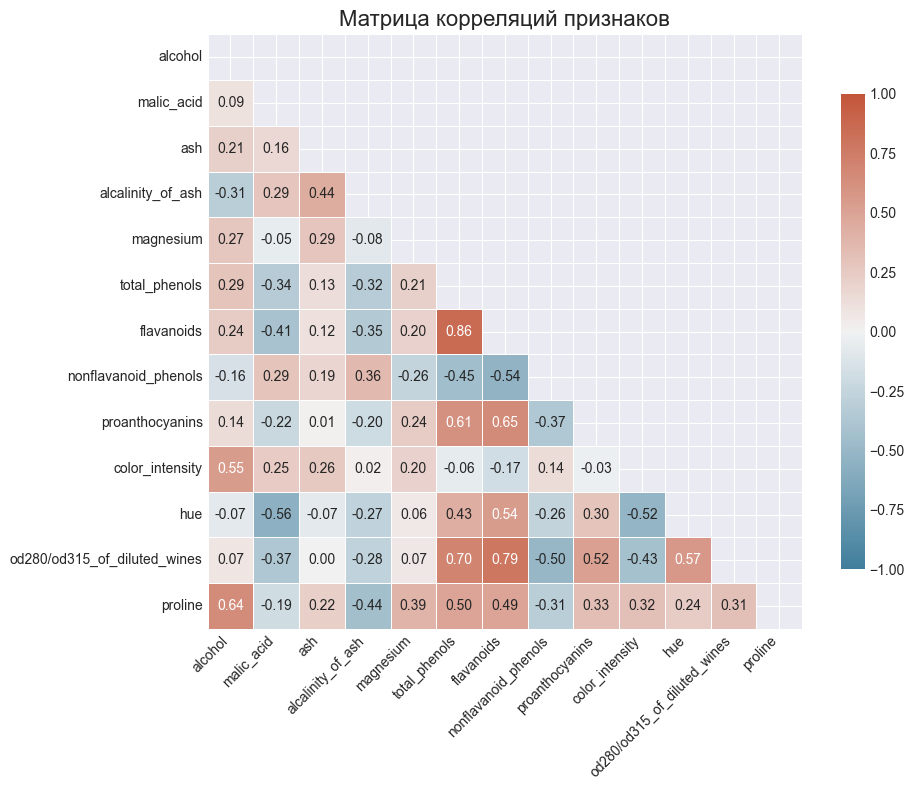

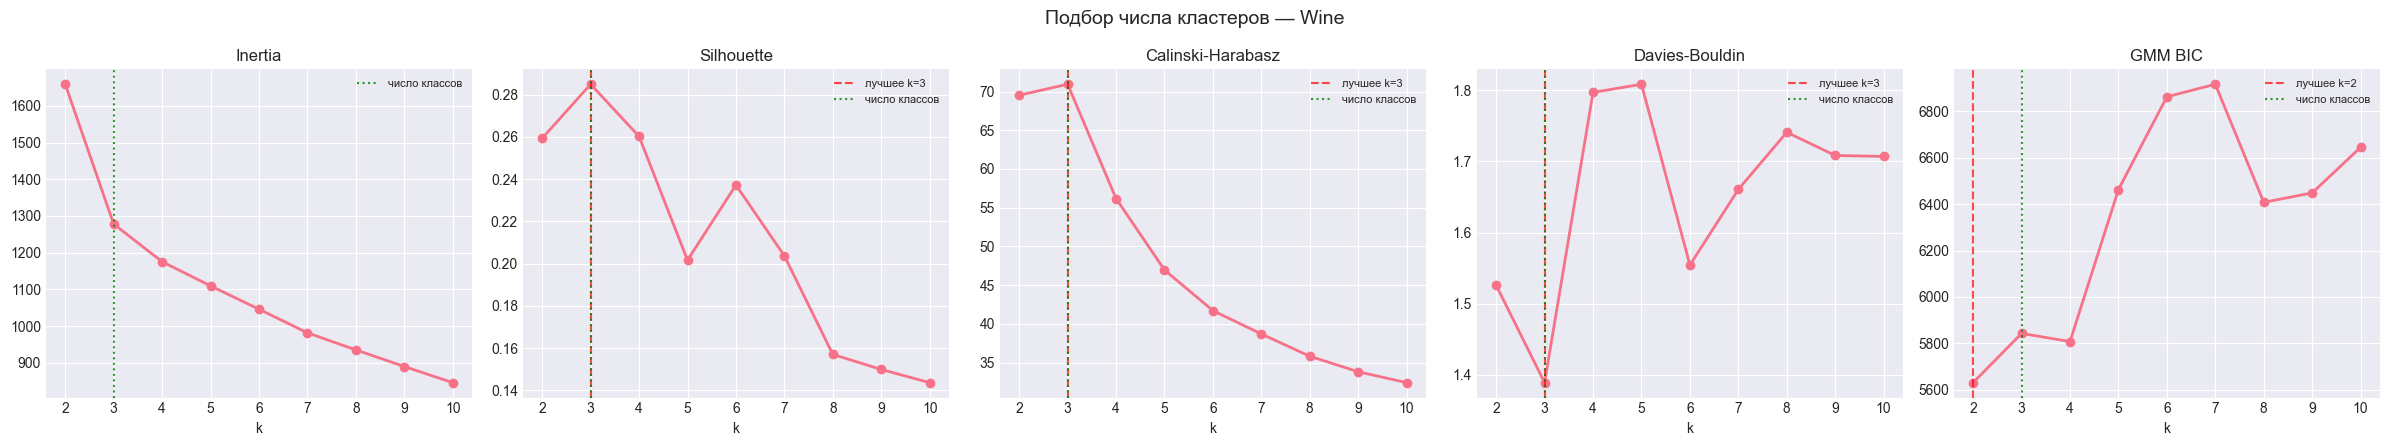

Рекомендация по силуэту: k = 3


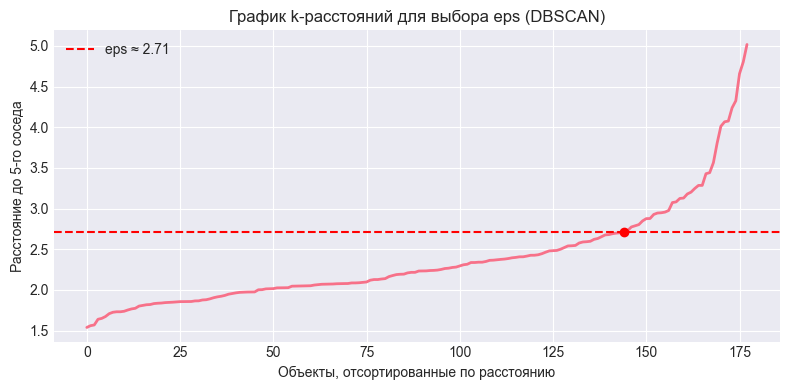

        KMeans: найдено кластеров = 3
 Agglomerative: найдено кластеров = 3
           GMM: найдено кластеров = 3
        DBSCAN: найдено кластеров = 1


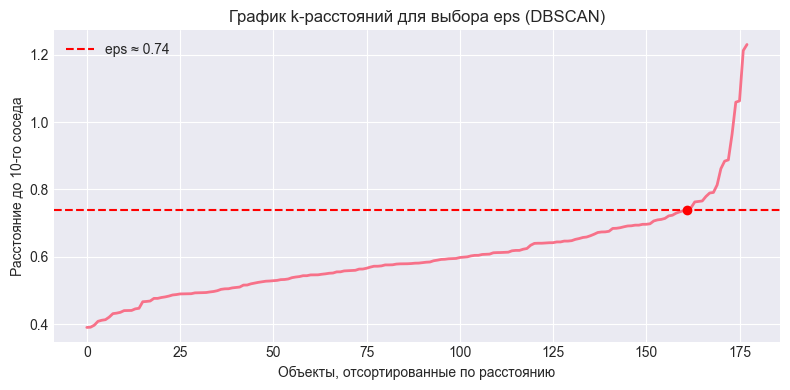

DBSCAN (UMAP): eps=0.738, min_samples=10, найдено кластеров = 3


,Clusters,"Noise, %",Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI,AMI,Homogeneity,Completeness,V-measure,Accuracy
Algorithm,,,,,,,,,,,
KMeans,3,0.000,0.285,70.940,1.389,0.897,0.875,0.879,0.873,0.876,0.966
Agglomerative,3,0.000,0.277,67.647,1.419,0.790,0.784,0.790,0.783,0.786,0.927
GMM,3,0.000,0.284,70.688,1.394,0.880,0.859,0.864,0.858,0.861,0.961
DBSCAN,1,10.112,NaN,NaN,NaN,0.000,0.089,0.063,0.208,0.096,0.421
DBSCAN (UMAP),3,0.000,0.278,69.219,1.382,0.774,0.772,0.778,0.770,0.774,0.921


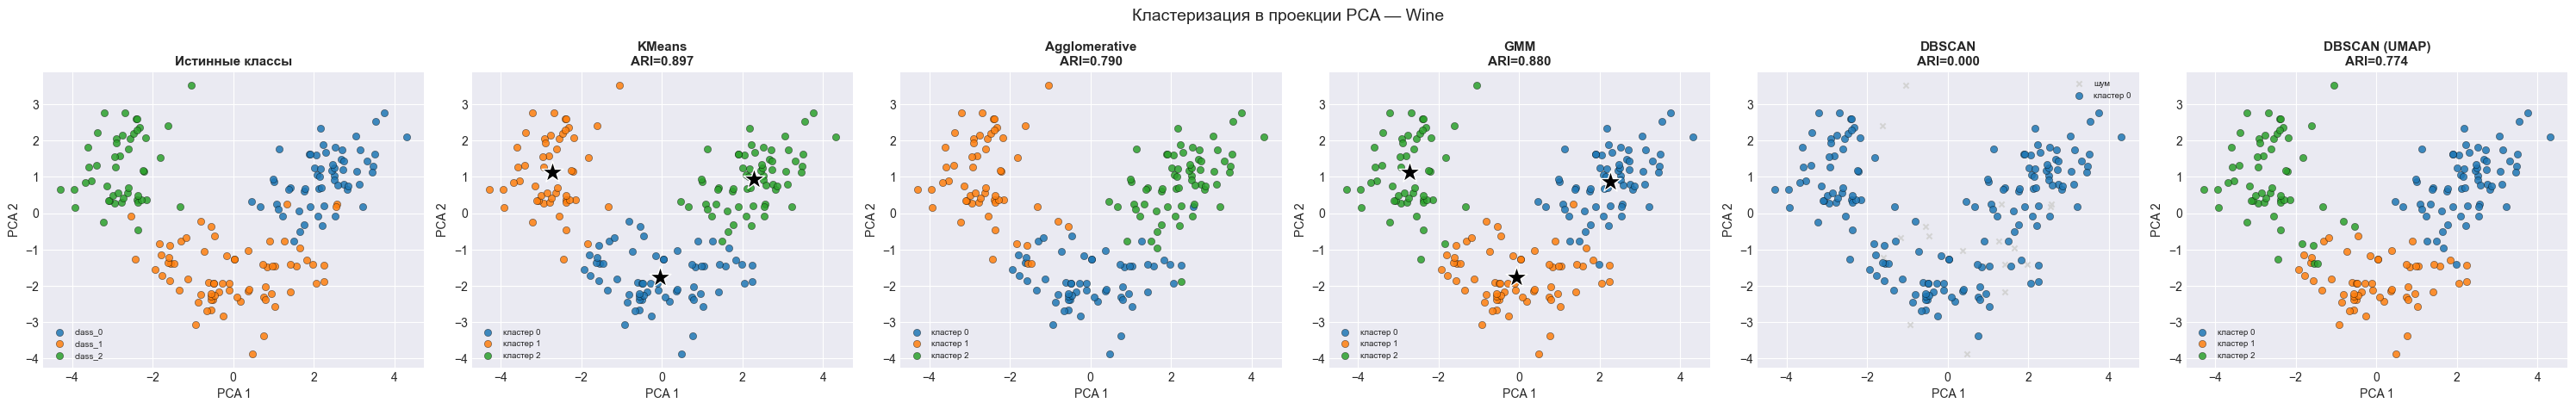

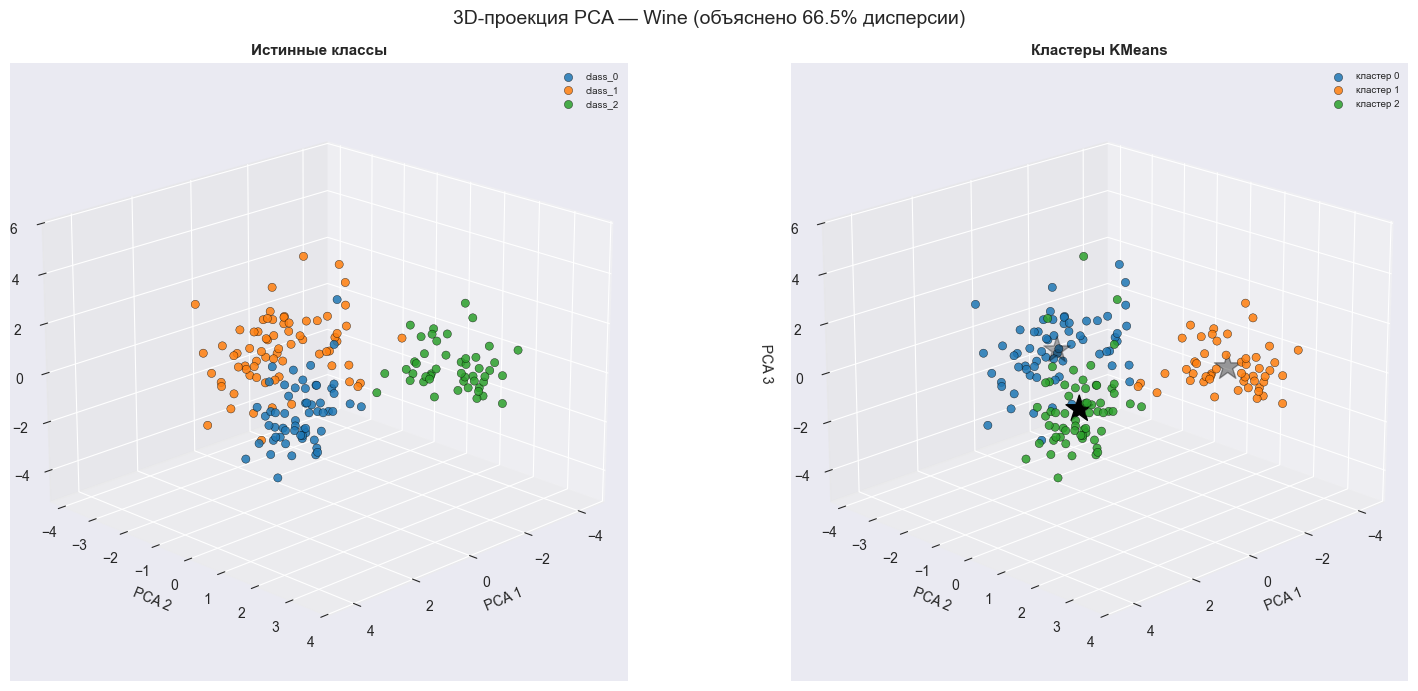

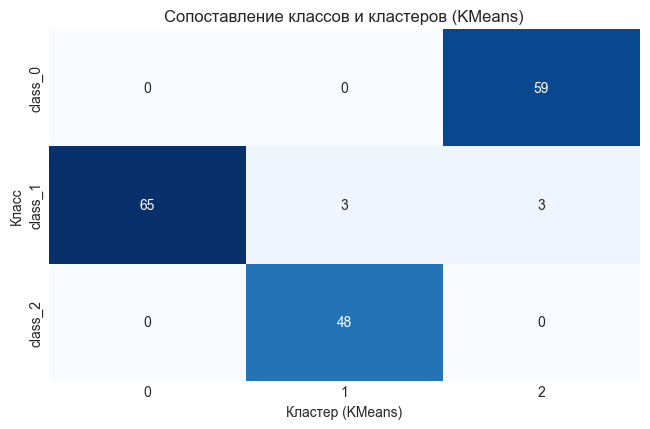

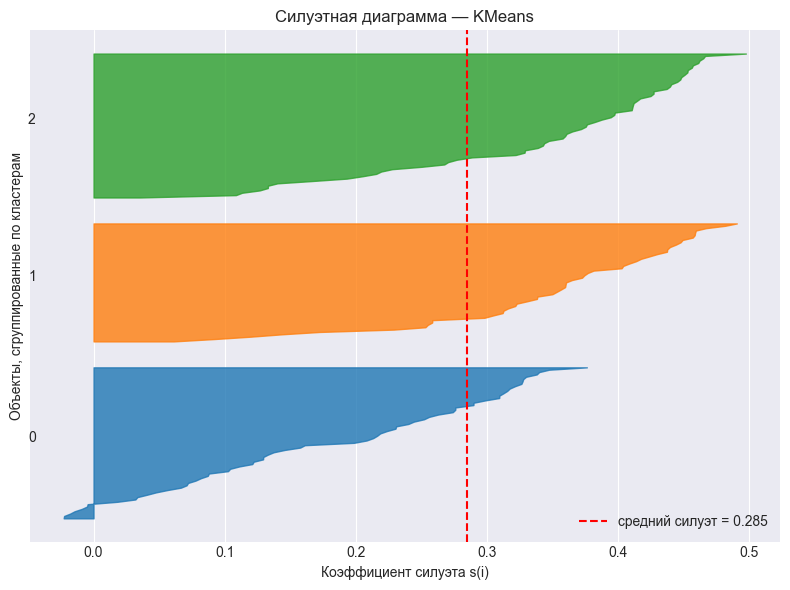

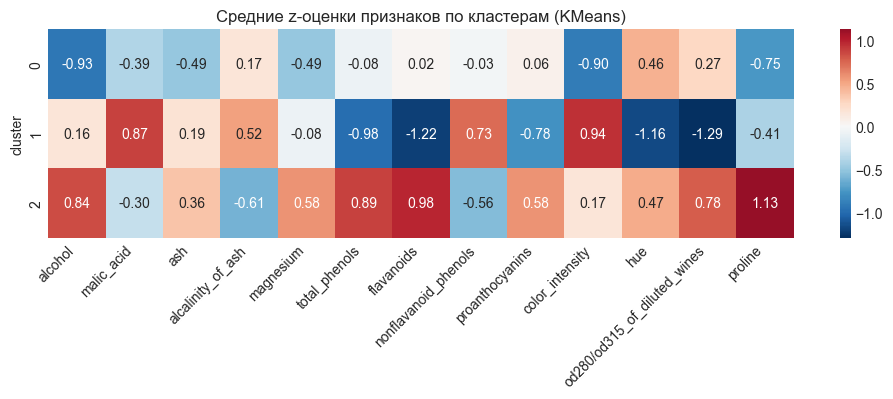

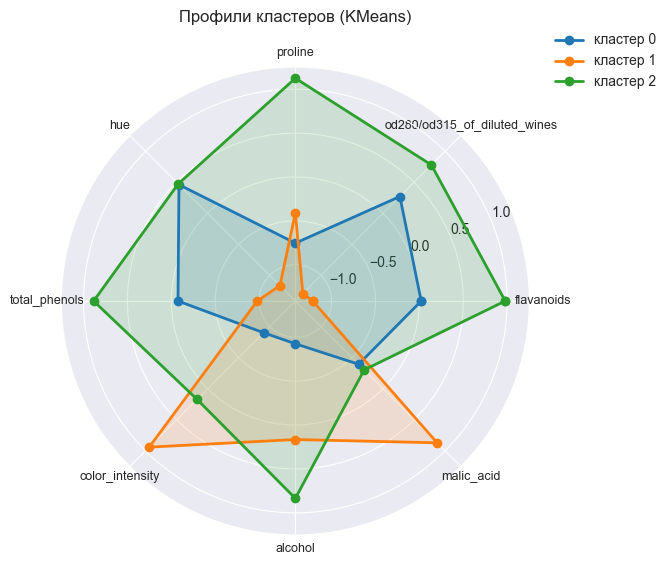


Лучший алгоритм: KMeans


In [26]:
viz_full = ClusteringVisualizer.from_sklearn("wine", dataset_name="Wine")
_ = viz_full.run_full_pipeline(embeddings=("PCA",), interactive=False)

## Выводы
- `ClusteringVisualizer` принимает любой датасет, кластеризует и строит 2D/3D-визуализацию.
- На Wine число кластеров k = 3 находится без меток, лучший алгоритм - KMeans (ARI ≈ 0.90).
- DBSCAN в высокой размерности не работает, после UMAP - работает.
- Внутренние метрики не равны качеству относительно классов.